In [2]:
# Datheon Machine Learning Internship
# Task 1: Iris Classification Pipeline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Step 1: Load and explore the Iris dataset

from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

df = X.copy()
df["species"] = y.map(dict(enumerate(iris.target_names)))

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nFlower species distribution:")
print(df["species"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset loaded successfully!
Number of rows and columns: (150, 5)

First 5 rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Flower species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


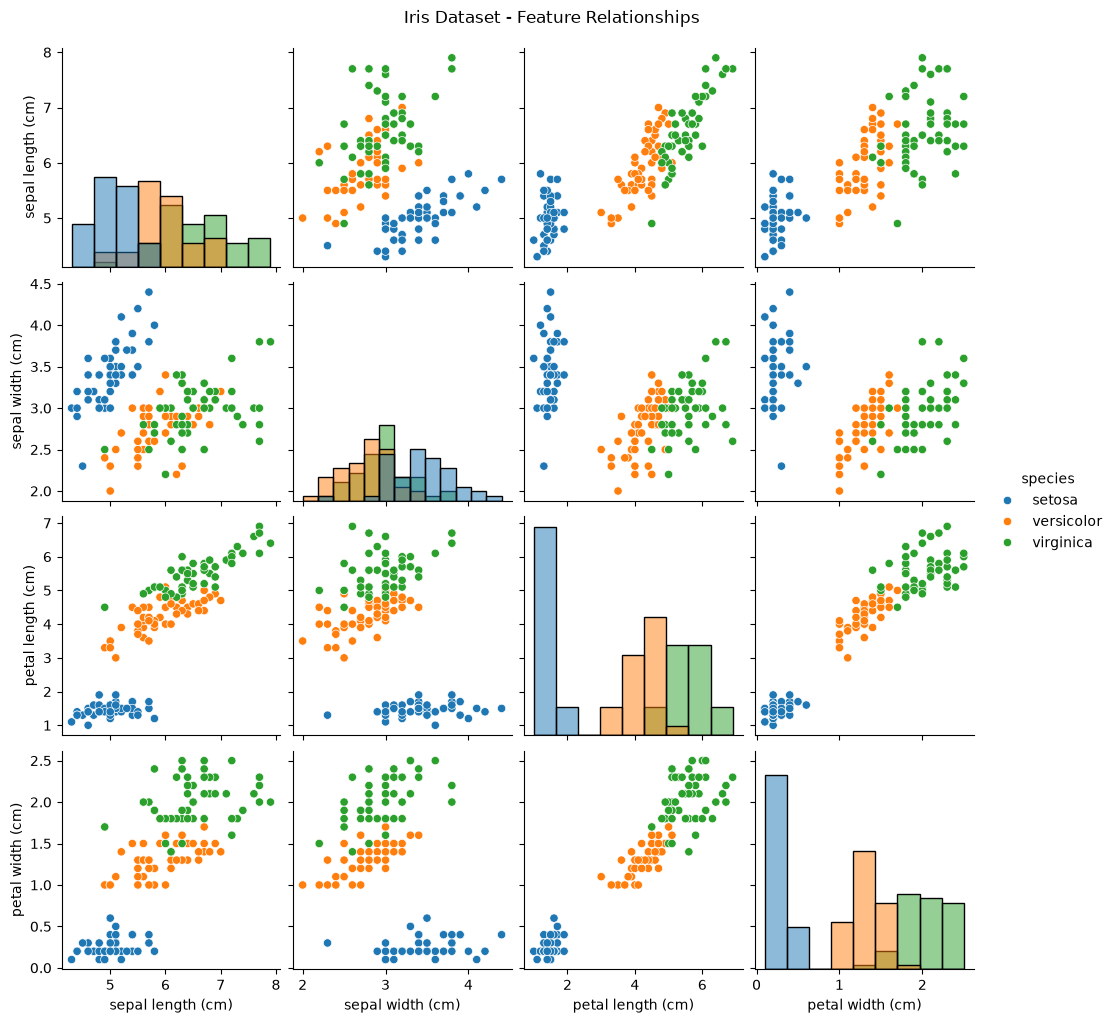

In [4]:
# Step 2: Visualize relationships between flower features

import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(df, hue="species", diag_kind="hist")
plt.suptitle("Iris Dataset - Feature Relationships", y=1.02)
plt.show()

In [5]:
# Step 3: Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training features:", X_train.shape[1])

Data split completed successfully!
Training samples: 120
Testing samples: 30
Training features: 4


In [6]:
# Step 4: Train Logistic Regression and Decision Tree

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=4,
            random_state=42
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [7]:
# Step 5: Evaluate and compare both models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
import pandas as pd

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

    print("\n", "=" * 40)
    print(name)
    print("=" * 40)
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    ))

results_df = pd.DataFrame(results).set_index("Model")

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


FINAL MODEL COMPARISON


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


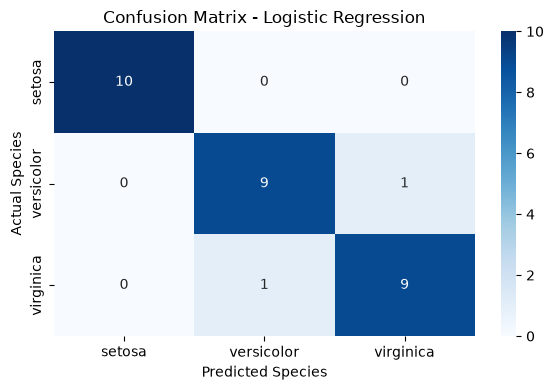

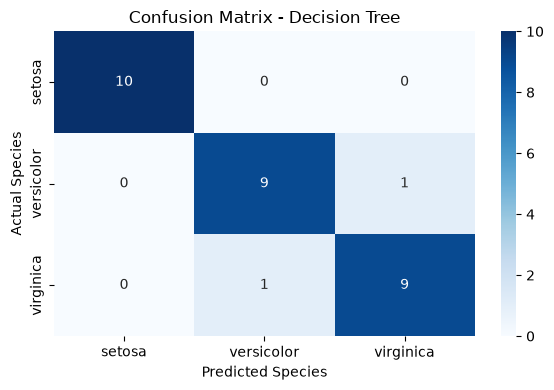

In [8]:
# Step 6: Confusion Matrix for both models

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=iris.target_names,
        yticklabels=iris.target_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.tight_layout()
    plt.show()

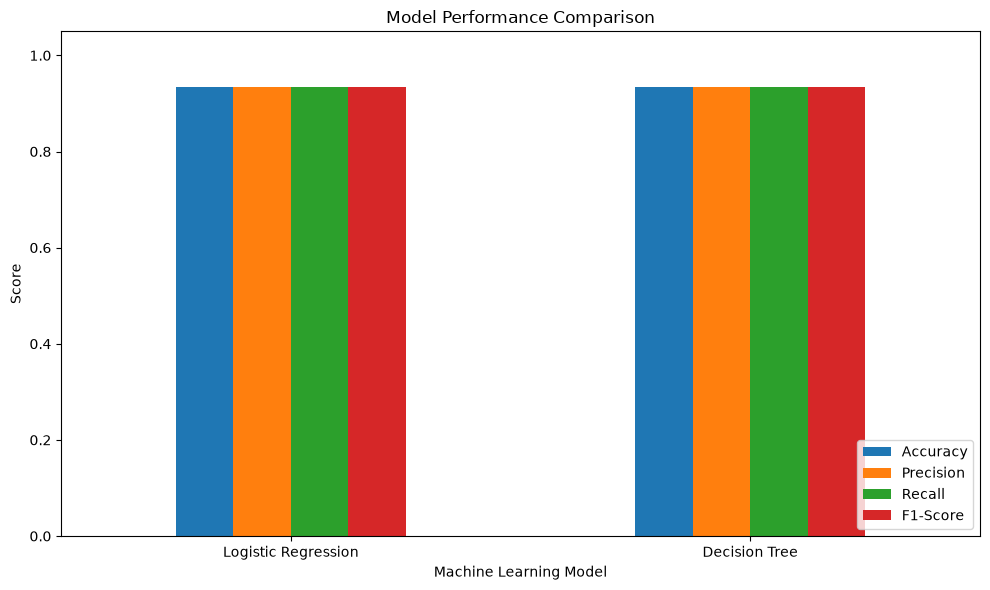

In [9]:
# Step 7: Visual comparison of model performance

import matplotlib.pyplot as plt

results_df.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [10]:
# Step 8: Save model comparison results

results_df.to_csv("classification_results.csv")

print("Model comparison results saved successfully!")
display(results_df.round(4))

Model comparison results saved successfully!


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


Variance retained by 2 PCA components: 0.9574


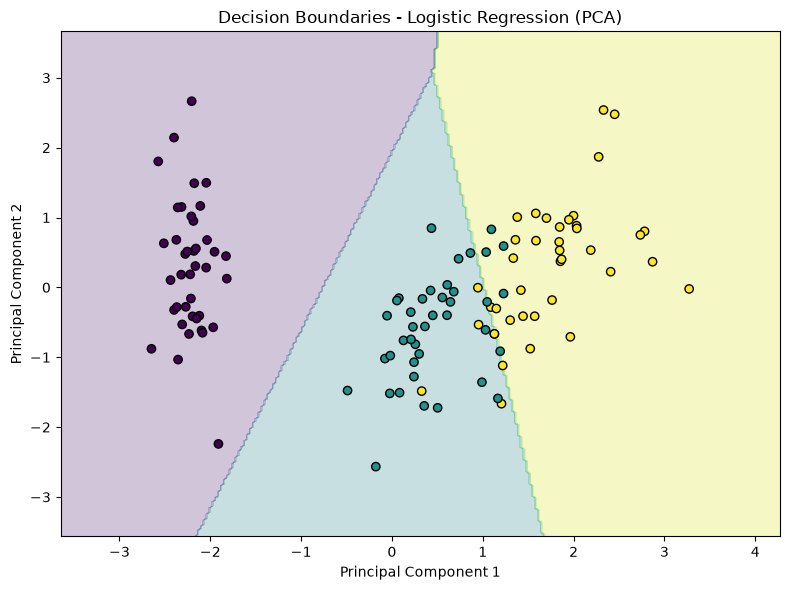

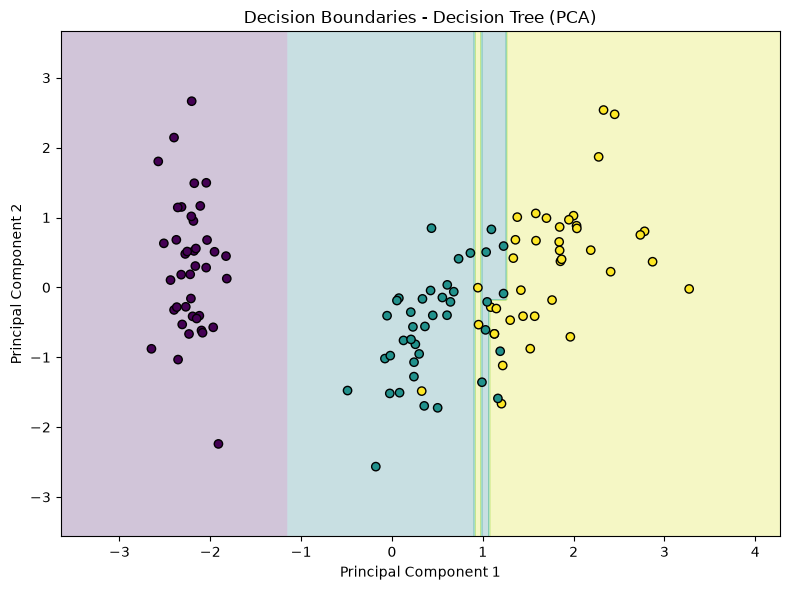

In [11]:
# Step 9: Visualize decision boundaries using PCA

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Scale training data and reduce it to 2 dimensions
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca = PCA(n_components=2)
X_train_2d = pca.fit_transform(X_train_scaled)

print("Variance retained by 2 PCA components:",
      round(pca.explained_variance_ratio_.sum(), 4))

for name, original_model in models.items():

    # Train a separate visualization model on 2D data
    visual_model = clone(original_model)
    visual_model.fit(X_train_2d, y_train)

    x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
    y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = visual_model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="viridis")

    plt.scatter(
        X_train_2d[:, 0],
        X_train_2d[:, 1],
        c=y_train,
        cmap="viridis",
        edgecolors="black"
    )

    plt.title(f"Decision Boundaries - {name} (PCA)")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.show()